In [2]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import HTML, display
from base64 import b64encode

print("OpenCV Version:", cv2.__version__)
print("Libraries Loaded Successfully")

OpenCV Version: 5.0.0
Libraries Loaded Successfully


In [3]:
os.makedirs('videos', exist_ok=True)

print("Please Upload A Video File:")
uploaded = files.upload()

for filename in uploaded.keys():
    dest = os.path.join('videos', filename)
    os.rename(filename, dest)
    print(f"File '{filename}' Moved To '{dest}'.")

print("\nContents Of Videos Folder:")
print(os.listdir('videos'))

Please Upload A Video File:


Saving slow_traffic_small.mp4 to slow_traffic_small.mp4
File 'slow_traffic_small.mp4' Moved To 'videos/slow_traffic_small.mp4'.

Contents Of Videos Folder:
['slow_traffic_small.mp4']


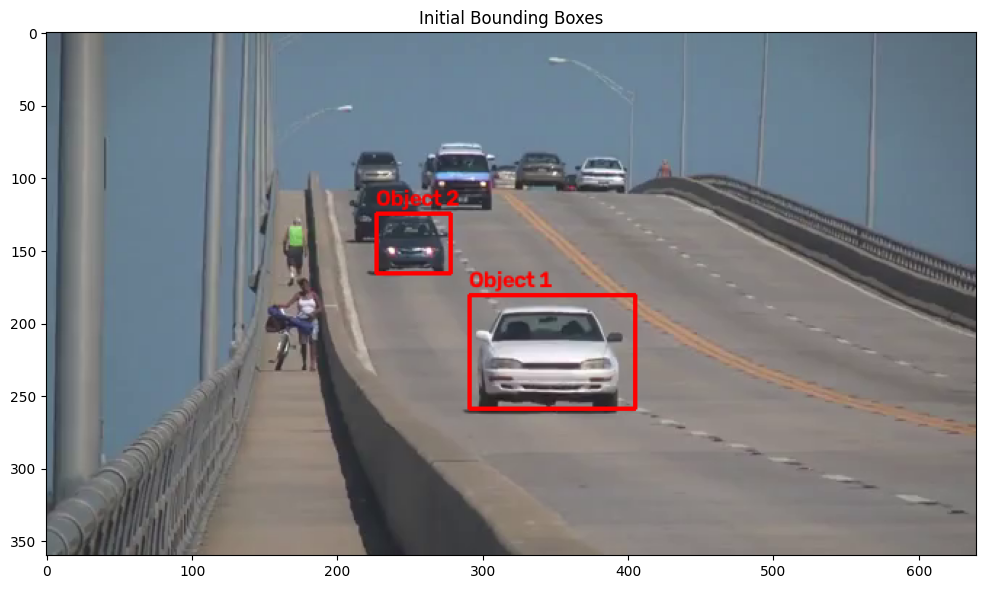

In [4]:
video_files = [f for f in os.listdir('videos') if f.lower().endswith(('.mp4', '.avi', '.mov'))]
video_input_file_name = os.path.join('videos', video_files[0])

video = cv2.VideoCapture(video_input_file_name)
ok, frame = video.read()

if not video.isOpened():
  print("Could Not Open Video")
else:
  width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
  height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))

bboxes = [
    (291, 181, 114, 78),
    (227, 125, 51, 41)
]

frame_copy = frame.copy()
for i, (x, y, w, h) in enumerate(bboxes):
  cv2.rectangle(frame_copy, (x, y), (x + w, y + h), (0, 0, 255), 2)
  cv2.putText(frame_copy, f"Object {i+1}", (x, y - 5),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)

plt.figure(figsize=(12, 8))

plt.imshow(cv2.cvtColor(frame_copy, cv2.COLOR_BGR2RGB))
plt.title("Initial Bounding Boxes")
plt.axis()

plt.show()

Tracking Done. Showing 12 Sample Frames.


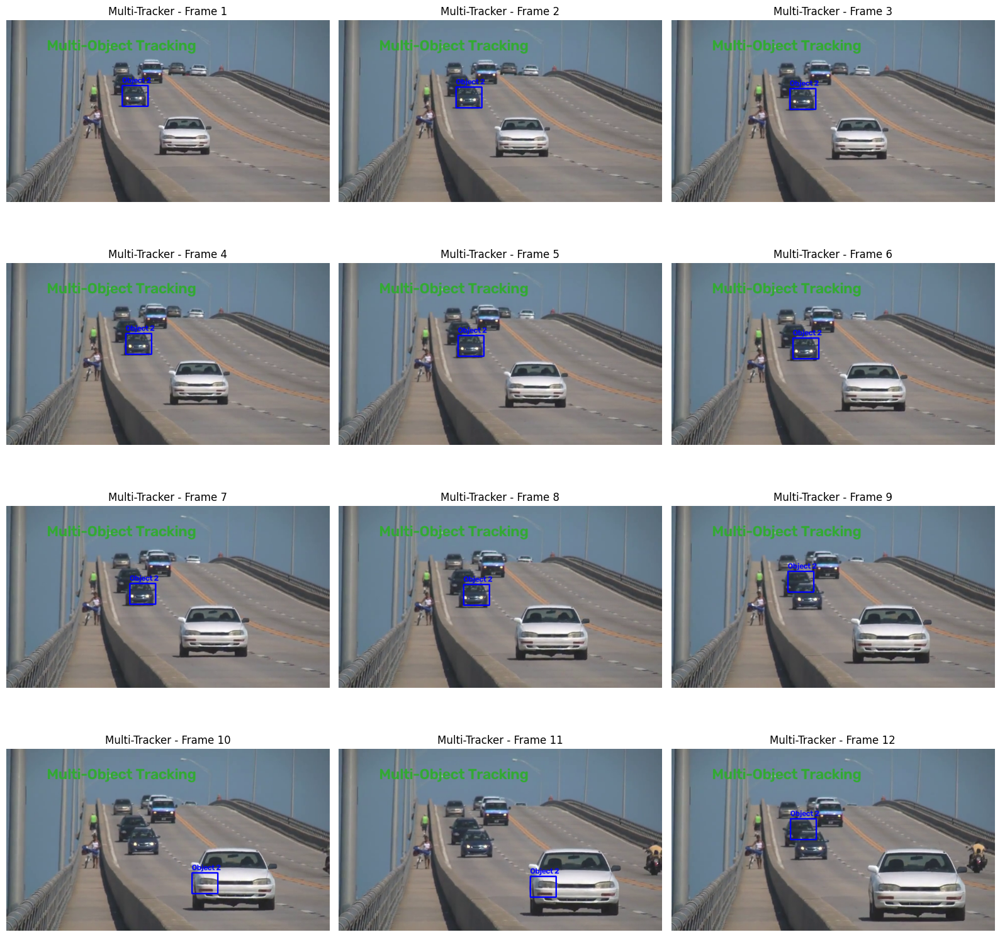

In [5]:
templates = []
for (x, y, w, h) in bboxes:
  template = frame[y:y+h, x:x+w]
  template_gray = cv2.cvtColor(template, cv2.COLOR_BGR2GRAY)
  templates.append(template_gray)

colors = [(0, 255, 0), (255, 0, 0), (0, 0, 255), (255, 255, 0)]
frame_to_show = []
max_show = 12
frame_count = 0

while True:
  ok, frame = video.read()
  if not ok:
    break

  frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

  for i, template in enumerate(templates):
    th, tw = template.shape

  res = cv2.matchTemplate(frame_gray, template, cv2.TM_CCOEFF_NORMED)
  min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)

  top_left = max_loc
  new_bbox = (top_left[0], top_left[1], tw, th)

  color = colors[i % len(colors)]
  cv2.rectangle(frame, top_left, (top_left[0] + tw, top_left[1] + th), color, 2)
  cv2.putText(frame, f"Object {i+1}", (top_left[0], top_left[1] - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

  cv2.putText(frame, "Multi-Object Tracking", (80, 60),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (50, 170, 50), 3)

  frame_count += 1
  if frame_count % 10 == 0 and len(frame_to_show) < max_show:
        frame_to_show.append(frame.copy())

video.release()
print(f"Tracking Done. Showing {len(frame_to_show)} Sample Frames.")

n = len(frame_to_show)
if n > 0:
  plt.figure(figsize=[16, 4 * ((n + 2) // 3)])
  for i in range(n):
        plt.subplot((n + 2) // 3, 3, i + 1)
        plt.imshow(cv2.cvtColor(frame_to_show[i], cv2.COLOR_BGR2RGB))
        plt.title(f"Multi-Tracker - Frame {i+1}")
        plt.axis('off')

  plt.tight_layout()
  plt.show()

In [6]:
video = cv2.VideoCapture(video_input_file_name)
ok, frame = video.read()

video_output_file_name = 'output-multi-tracking.mp4'
video_out = cv2.VideoWriter(video_output_file_name, cv2.VideoWriter_fourcc(*'mp4v'), 10, (width, height))

frame_count = 0
while True:
    ok, frame = video.read()
    if not ok:
        break

    frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    for i, template in enumerate(templates):
        th, tw = template.shape
        res = cv2.matchTemplate(frame_gray, template, cv2.TM_CCOEFF_NORMED)
        min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)
        top_left = max_loc
        color = colors[i % len(colors)]
        cv2.rectangle(frame, top_left, (top_left[0] + tw, top_left[1] + th), color, 2)
        cv2.putText(frame, f"Object {i+1}", (top_left[0], top_left[1] - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

    video_out.write(frame)

video.release()
video_out.release()

if os.path.exists(video_output_file_name):
    mp4 = open(video_output_file_name, 'rb').read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
    display(HTML(f"""
    <video width=1024 controls>
      <source src="{data_url}" type="video/mp4">
    </video>
    """))
    print("Output Video Created Successfully")
else:
    print("Output Video Not Found")

Output Video Created Successfully
